# California Housing Price Prediction

## 1. Project Overview

The objective of this project is to build a Machine Learning model that predicts the **median house value of California districts** from demographic and geographic features.

The workflow is:

1. Exploratory Data Analysis (EDA), including data-quality checks
2. A **fair experimental design**: one fixed train/test split shared by every model
3. Linear Regression baselines under different data-preparation strategies
4. Feature engineering
5. Model comparison with 5-fold cross-validation
6. Final evaluation and model interpretation

**Central question:** the target variable is right-censored (prices above $500,000 are capped). Does removing those rows really improve the model, or are other data-quality issues (extreme outliers in the features) responsible for the poor baseline performance?

## 2. Business Problem

Accurately estimating housing prices is valuable for real estate agencies, property investors, financial institutions and home buyers. The goal is to estimate the median house value of a district using demographic and geographic variables.

## 3. Dataset

California Housing dataset (scikit-learn): **20,640 districts** and **8 predictors** describing demographic and housing characteristics of California district.

The target `Price` is the median house value expressed in **units of \$100,000** (so `Price = 2.5` means \$250,000).

| Attribute | Description |
|-----------|-------------|
| MedInc | median income in block group (in $10,000) |
| HouseAge | median house age in block group |
| AveRooms | average number of rooms per household |
| AveBedrms | average number of bedrooms per household |
| Population | block group population |
| AveOccup | average number of household members |
| Latitude | block group latitude |
| Longitude | block group longitude |

## 4. Setup and Data Loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

%matplotlib inline
sns.set_theme(style="whitegrid")

SEED = 42
CAP = 5.0  # prices >= 5.0 ($500,000) are censored in this dataset
IMAGES = Path("../images")
IMAGES.mkdir(exist_ok=True)

def save_fig(name):
    plt.savefig(IMAGES / name, dpi=300, bbox_inches="tight")

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.rename(columns={"MedHouseVal": "Price"})
FEATURES = list(housing.feature_names)

print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 5. Exploratory Data Analysis (EDA)

### 5.1 General structure

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
HouseAge,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
AveRooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
AveBedrms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
Population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
AveOccup,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
Latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
Longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
Price,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000


### 5.2 Correlation analysis

The heatmap shows the linear relationship between variables. `MedInc` is expected to be the strongest linear predictor of `Price`.

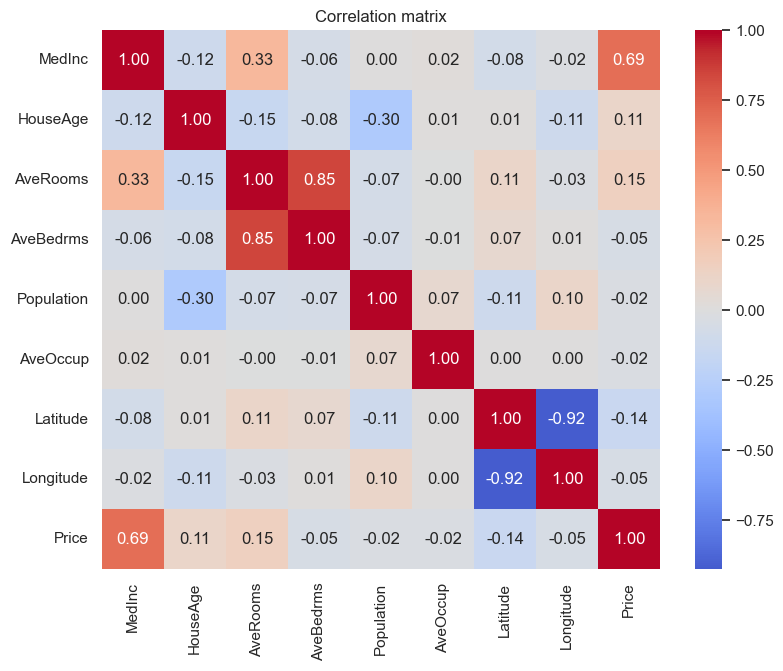

In [5]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
save_fig("correlation_heatmap.png")
plt.show()

### 5.3 Target distribution and right-censoring

House values above $500,000 are recorded at the cap value, creating an artificial spike at the right edge of the distribution.

Censored districts: 992 (4.81% of the data)


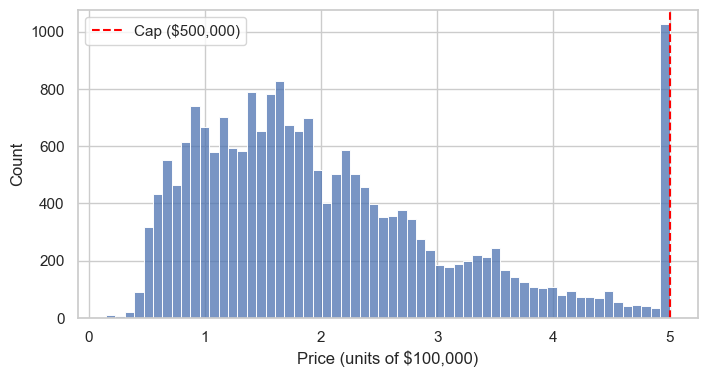

In [6]:
censored = df["Price"] >= CAP
print(f"Censored districts: {censored.sum()} ({censored.mean():.2%} of the data)")

plt.figure(figsize=(8, 4))
sns.histplot(df["Price"], bins=60)
plt.axvline(CAP, color="red", linestyle="--", label="Cap ($500,000)")
plt.xlabel("Price (units of $100,000)")
plt.legend()
save_fig("original_price.png")
plt.show()

### 5.4 Geographic view

Location is a major price driver in real estate. Coastal areas around San Francisco and Los Angeles stand out.

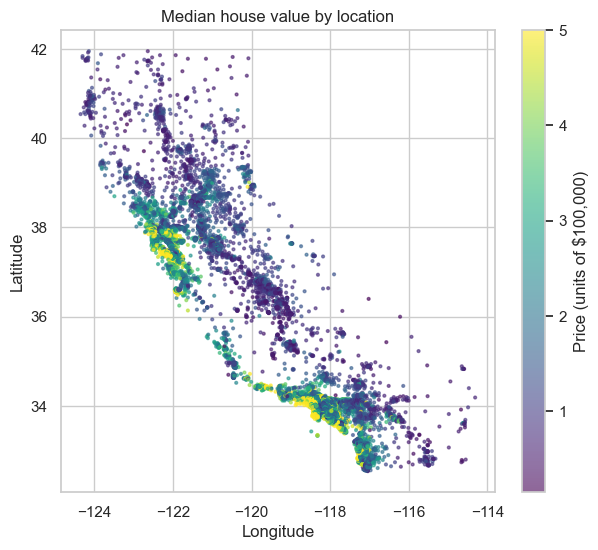

In [7]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(df["Longitude"], df["Latitude"], c=df["Price"], s=4, cmap="viridis", alpha=0.6)
plt.colorbar(sc, label="Price (units of $100,000)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Median house value by location")
save_fig("price_map.png")
plt.show()

### 5.5 Outliers in the predictors

The census-derived averages (`AveRooms`, `AveBedrms`, `AveOccup`) are ratios computed for each district, so districts with very few households can produce **absurd values** (for example, hundreds of people per household). Extreme values like these can dominate the squared error of a linear model, so they are checked here before drawing any conclusion about the censoring.

,count,mean,std,min,1%,50%,99%,max
AveRooms,20640.0,5.43,2.47,0.85,2.58,5.23,10.36,141.91
AveBedrms,20640.0,1.10,0.47,0.33,0.87,1.05,2.13,34.07
AveOccup,20640.0,3.07,10.39,0.69,1.54,2.82,5.39,1243.33
Population,20640.0,1425.48,1132.46,3.00,88.00,1166.00,5805.83,35682.00


Districts with AveOccup > 10: 37 (0.18%)
Share of those that are also price-capped: 10.8%


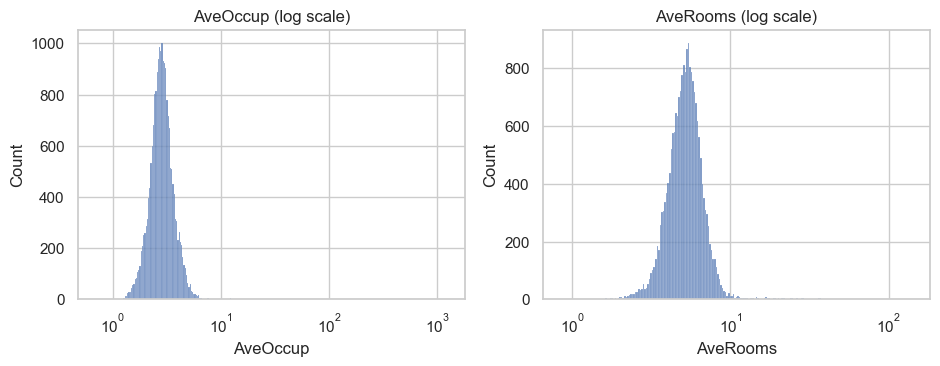

In [8]:
cols = ["AveRooms", "AveBedrms", "AveOccup", "Population"]
display(df[cols].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2))

extreme = df["AveOccup"] > 10
print(f"Districts with AveOccup > 10: {extreme.sum()} ({extreme.mean():.2%})")
print(f"Share of those that are also price-capped: {(df.loc[extreme, 'Price'] >= CAP).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["AveOccup"], log_scale=True, ax=axes[0]); axes[0].set_title("AveOccup (log scale)")
sns.histplot(df["AveRooms"], log_scale=True, ax=axes[1]); axes[1].set_title("AveRooms (log scale)")
save_fig("feature_outliers.png")
plt.show()

## 6. Experimental Design

To make every comparison **fair**:

- One train/test split (80/20, fixed seed) is created **once** and reused by all models.
- Every model is evaluated on the **same full test set**, including censored observations, because those are real districts the model will face in practice.
- Any cleaning or clipping is learned **from the training set only**, so no information leaks from the test set.
- Besides RMSE, MAE and R², the RMSE on the *uncensored* part of the test set is also reported, as a reference.

> In the first version of this project, the cleaned model was evaluated on a test set without the expensive houses. That test set is easier to predict, so the improvement could not be attributed to the cleaning itself.

In [12]:
X = df[FEATURES]
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

y_test_arr = y_test.to_numpy()
unc = y_test_arr < CAP          # uncensored mask for the test set

def rmse(a, b):
    return np.sqrt(mean_squared_error(a, b))

results = []

def evaluate(name, model, X_tr, y_tr, X_te):
    """Fit on the given training data, evaluate on the shared test set."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    results.append({
        "Model": name,
        "RMSE": rmse(y_test_arr, pred),
        "MAE": mean_absolute_error(y_test_arr, pred),
        "R2": r2_score(y_test_arr, pred),
        "RMSE (uncensored test)": rmse(y_test_arr[unc], pred[unc]),
    })
    return model, pred

print(f"Train: {X_train.shape[0]} rows | Test: {X_test.shape[0]} rows "
      f"({(~unc).sum()} censored in test)")

Train: 16512 rows | Test: 4128 rows (184 censored in test)


## 7. Linear Regression Experiments

Four strategies are compared with the same algorithm:

| Experiment | Training data | Feature outliers |
|-----------|---------------|------------------|
| A. Baseline | all rows | untouched |
| B. Drop censored | rows with `Price < 5` | untouched |
| C. Clip outliers | all rows | capped at the 99th percentile of the training set |
| D. Both | rows with `Price < 5` | capped at the 99th percentile of the training set |

A small custom transformer learns the clipping limits from the training data only.

In [13]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Caps the given columns at an upper quantile learned during fit()."""

    def __init__(self, columns=None, upper=0.99):
        self.columns = columns
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        cols = [c for c in self.columns if c in X.columns]
        self.upper_ = {c: X[c].quantile(self.upper) for c in cols}
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for c, limit in self.upper_.items():
            X[c] = X[c].clip(upper=limit)
        return X

CLIP_COLS = ["AveRooms", "AveBedrms", "AveOccup", "Population", "RoomsPerPerson", "BedroomRatio"]

In [14]:
not_cens_train = (y_train < CAP).to_numpy()

# A. Baseline
lm_A, pred_A = evaluate("A. Baseline (all data)",
                        LinearRegression(),
                        X_train,
                        y_train,
                        X_test)

# B. Drop censored rows from the training set only
lm_B, pred_B = evaluate("B. Drop censored (train only)",
                        LinearRegression(),
                        X_train[not_cens_train],
                        y_train[not_cens_train],
                        X_test)

# C. Clip feature outliers, keep every row (incluiding censored rows)
lm_C, pred_C = evaluate("C. Clip feature outliers",
                        make_pipeline(QuantileClipper(CLIP_COLS), LinearRegression()),
                        X_train,
                        y_train,
                        X_test)

# D. Clips feauture outliers and drops censored rows
lm_D, pred_D = evaluate("D. Drop censored + clip",
                        make_pipeline(QuantileClipper(CLIP_COLS), LinearRegression()),
                        X_train[not_cens_train],
                        y_train[not_cens_train],
                        X_test)

res = pd.DataFrame(results).set_index("Model")
res["MAE ($)"] = (res["MAE"] * 100_000).round(0)
res.round(4)

,RMSE,MAE,R2,RMSE (uncensored test),MAE ($)
Model,,,,,
A. Baseline (all data),0.7456,0.5332,0.5758,0.6578,53320.0
B. Drop censored (train only),0.7444,0.5246,0.5772,0.6486,52465.0
C. Clip feature outliers,0.6794,0.4978,0.6477,0.5996,49785.0
D. Drop censored + clip,0.6844,0.4907,0.6425,0.5952,49074.0


In [22]:
baseline = "A. Baseline (all data)"
metrics = ["RMSE", "MAE", "R2", "RMSE (uncensored test)"]

base = res.loc[baseline, metrics]
abs_change = res[metrics].sub(base, axis=1)
pct_change = abs_change.div(base, axis=1) * 100

print("Percentage change vs baseline (%)")
display(pct_change.drop(index=baseline).round(2))

Percentage change vs baseline (%)


,RMSE,MAE,R2,RMSE (uncensored test)
Model,,,,
B. Drop censored (train only),-0.16,-1.60,0.24,-1.40
C. Clip feature outliers,-8.87,-6.63,12.49,-8.85
D. Drop censored + clip,-8.21,-7.96,11.59,-9.53


### 7.1 Experiment Comparisson

Considering the unchanged data model as the baseline, the experiment B doesn´t shows a remarcable improvement after removing censored values, reducing RMSE only for $0.16%$ and icreases the explained variance (R-squared) only for $0.24%$. On the other hand, the experiment C reduces RMSE almost on $9%$ and increases the explained variance on $12.5%$. Then we can say the poor baseline was mostly caused by **extreme outliers in the features**, not by the censored target.



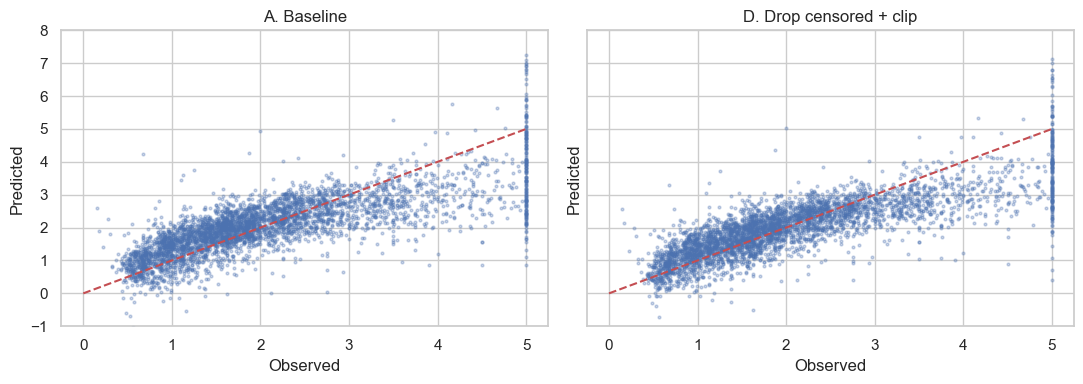

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, pred, title in zip(axes, [pred_A, pred_D], ["A. Baseline", "D. Drop censored + clip"]):
    ax.scatter(y_test_arr, pred, s=4, alpha=0.3)
    ax.plot([0, 5], [0, 5], "r--")
    ax.set_title(title); ax.set_xlabel("Observed"); ax.set_ylabel("Predicted")
    ax.set_ylim(-1, 8)
plt.tight_layout()
save_fig("actual_vs_predicted_linear.png")
plt.show()

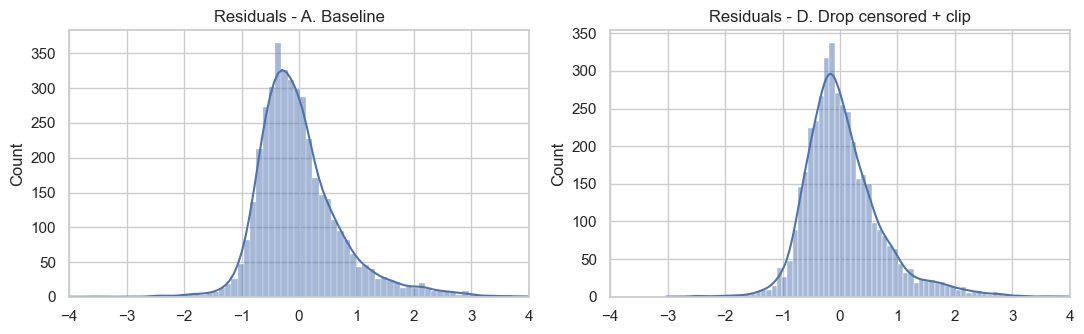

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for ax, pred, title in zip(axes, [pred_A, pred_D], ["A. Baseline", "D. Drop censored + clip"]):
    sns.histplot(y_test_arr - pred, kde=True, ax=ax)
    ax.set_title(f"Residuals - {title}")
    ax.set_xlim(-4, 4)
plt.tight_layout()
save_fig("residuals_linear.png")
plt.show()

### 7.2 Coefficients

Coefficients of the baseline model. Interpret them with care: `Latitude` and `Longitude` act together as a proxy for location, and `AveRooms` / `AveBedrms` are strongly correlated with each other (multicollinearity), so individual coefficients can have counter-intuitive signs.

In [17]:
coef_df = pd.DataFrame({"Coefficient": lm_A.coef_}, index=FEATURES)
display(coef_df.round(4))

terms = " ".join(f"{c:+.4f}*{n}" for n, c in zip(FEATURES, lm_A.coef_))
print(f"Price = {lm_A.intercept_:.4f} {terms}")

,Coefficient
MedInc,0.4487
HouseAge,0.0097
AveRooms,-0.1233
AveBedrms,0.7831
Population,-0.0000
AveOccup,-0.0035
Latitude,-0.4198
Longitude,-0.4337


Price = -37.0233 +0.4487*MedInc +0.0097*HouseAge -0.1233*AveRooms +0.7831*AveBedrms -0.0000*Population -0.0035*AveOccup -0.4198*Latitude -0.4337*Longitude


## 8. Feature Engineering

New variables built **only from the same row** (no information from other rows, so there is no leakage):

- `BedroomRatio`: share of rooms that are bedrooms
- `RoomsPerPerson`: living space per resident
- `DistNearestCity`: distance in km to the nearest of five major California cities (Los Angeles, San Francisco, San Diego, San Jose, Sacramento). This captures the price premium of urban areas better than raw latitude/longitude.

In [19]:
CITIES = {
    "Los Angeles": (34.05, -118.24),
    "San Francisco": (37.77, -122.42),
    "San Diego": (32.72, -117.16),
    "San Jose": (37.34, -121.89),
    "Sacramento": (38.58, -121.49),
}

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

def add_features(data):
    data = data.copy()
    data["BedroomRatio"] = data["AveBedrms"] / data["AveRooms"]
    data["RoomsPerPerson"] = data["AveRooms"] / data["AveOccup"]
    dists = np.column_stack([
        haversine_km(data["Latitude"], data["Longitude"], lat, lon)
        for lat, lon in CITIES.values()
    ])
    data["DistNearestCity"] = dists.min(axis=1)
    return data

X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)
X_train_fe.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,BedroomRatio,RoomsPerPerson,DistNearestCity
14196,3.2596,33.0,5.017657,1.006421,2300.0,3.691814,32.71,-117.03,0.200576,1.359130,12.213004
8267,3.8125,49.0,4.473545,1.041005,1314.0,1.738095,33.77,-118.16,0.232703,2.573820,31.997881
17445,4.1563,4.0,5.645833,0.985119,915.0,2.723214,34.66,-120.48,0.174486,2.073224,216.519120
14265,1.9425,36.0,4.002817,1.033803,1418.0,3.994366,32.69,-117.11,0.258269,1.002116,5.745833
2271,3.5542,43.0,6.268421,1.134211,874.0,2.300000,36.78,-119.80,0.180940,2.725400,195.623617


## 9. Model Comparison with Cross-Validation

Instead of trusting a single split, each model is evaluated with **5-fold cross-validation on the training set**. The test set stays untouched until the final evaluation.

Models compared, each on the base features and on the engineered features:

- Linear Regression and Ridge (with clipping and scaling)
- Random Forest
- Histogram Gradient Boosting

Cross-validation uses all training rows (censored included), since the tree-based models handle a capped target without trouble.

In [20]:
def make_models():
    return {
        "Linear Regression": make_pipeline(QuantileClipper(CLIP_COLS), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(QuantileClipper(CLIP_COLS), StandardScaler(), Ridge(alpha=1.0)),
        "Random Forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=2,
                                               n_jobs=-1, random_state=SEED),
        "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=SEED),
    }

feature_sets = {
    "Base": (X_train, X_test),
    "Engineered": (X_train_fe, X_test_fe),
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []

for fs_name, (Xtr, _) in feature_sets.items():
    for model_name, model in make_models().items():
        cv = cross_validate(model, Xtr, y_train, cv=kf,
                            scoring=("neg_root_mean_squared_error", "r2"))
        rmse_cv = -cv["test_neg_root_mean_squared_error"]
        cv_rows.append({
            "Features": fs_name,
            "Model": model_name,
            "CV RMSE (mean)": rmse_cv.mean(),
            "CV RMSE (std)": rmse_cv.std(),
            "CV R2 (mean)": cv["test_r2"].mean(),
        })

cv_df = pd.DataFrame(cv_rows).sort_values("CV RMSE (mean)").reset_index(drop=True)
cv_df.round(4)

,Features,Model,CV RMSE (mean),CV RMSE (std),CV R2 (mean)
0,Engineered,Hist Gradient Boosting,0.4619,0.0106,0.8403
1,Base,Hist Gradient Boosting,0.4722,0.0115,0.8331
2,Engineered,Random Forest,0.4910,0.0125,0.8196
3,Base,Random Forest,0.5100,0.0120,0.8053
4,Engineered,Ridge,0.6487,0.0152,0.6851
5,Engineered,Linear Regression,0.6487,0.0152,0.6851
6,Base,Linear Regression,0.6689,0.0146,0.6652
7,Base,Ridge,0.6689,0.0146,0.6652


In [ ]:
plt.figure(figsize=(9, 4.5))
sns.barplot(data=cv_df, y="Model", x="CV RMSE (mean)", hue="Features")
plt.title("Cross-validated RMSE (lower is better)")
save_fig("cv_comparison.png")
plt.show()

## 10. Final Evaluation on the Test Set

The best configuration according to cross-validation is refit on the full training set and evaluated **once** on the test set.

In [ ]:
best = cv_df.iloc[0]
print(f"Best configuration: {best['Model']} with {best['Features']} features")

Xtr_best, Xte_best = feature_sets[best["Features"]]
best_model, pred_best = evaluate(f"Final: {best['Model']} ({best['Features']})",
                                 make_models()[best["Model"]], Xtr_best, y_train, Xte_best)

res = pd.DataFrame(results).set_index("Model")
res["MAE ($)"] = (res["MAE"] * 100_000).round(0)
res.round(4)

### 10.1 Predicted vs Observed and Residuals

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test_arr, pred_best, s=4, alpha=0.3)
axes[0].plot([0, 5], [0, 5], "r--")
axes[0].set_xlabel("Observed"); axes[0].set_ylabel("Predicted"); axes[0].set_title("Final model")
sns.histplot(y_test_arr - pred_best, kde=True, ax=axes[1])
axes[1].set_title("Residuals - final model"); axes[1].set_xlim(-4, 4)
plt.tight_layout()
save_fig("final_model_diagnostics.png")
plt.show()

### 10.2 Where does the model fail?

Mean absolute error by price range. The censored group (>= $500,000) is expected to be the hardest: the true price is unknown beyond the cap.

In [ ]:
err = pd.DataFrame({"Price": y_test_arr, "AbsError": np.abs(y_test_arr - pred_best)})
err["Range"] = pd.cut(err["Price"], [0, 1, 2, 3, 4, CAP, 6],
                      labels=["<100k", "100-200k", "200-300k", "300-400k", "400-500k", ">=500k (capped)"],
                      right=False)
by_range = err.groupby("Range", observed=True)["AbsError"].agg(["mean", "count"])
by_range["mean ($)"] = (by_range["mean"] * 100_000).round(0)
display(by_range)

by_range["mean ($)"].plot(kind="bar", figsize=(8, 4), rot=30)
plt.ylabel("Mean absolute error ($)")
save_fig("error_by_price_range.png")
plt.show()

### 10.3 Feature importance

Permutation importance on the test set: how much the RMSE worsens when a feature is shuffled.

In [ ]:
perm = permutation_importance(best_model, Xte_best, y_test, n_repeats=5, random_state=SEED,
                              scoring="neg_root_mean_squared_error", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=Xte_best.columns).sort_values()

plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.xlabel("Increase in RMSE when shuffled")
plt.title("Permutation importance")
save_fig("feature_importance.png")
plt.show()

## 11. Conclusions

> **Fill this in after running the notebook, using your real numbers.** Suggested structure:

1. **What caused the poor baseline?** Compare experiments A, B, C and D (section 7). Was it the censoring, the feature outliers, or both?
2. **How much did better models help?** Compare the linear baseline with Random Forest and Gradient Boosting (sections 9 and 10).
3. **Did feature engineering help?** Compare *Base* vs *Engineered* in the cross-validation table.
4. **Where does the final model fail?** Use section 10.2 (price ranges) and the censored districts.
5. **Practical meaning:** translate the final MAE into dollars (for example, "the typical error is about $X").

## 12. Limitations and Future Improvements

- The target is capped at $500,000, so predictions for expensive districts are unreliable by construction. Methods designed for censored targets (for example, Tobit-type models) could be explored.
- Data are aggregated at district level, so the model predicts a district's median value, not the price of an individual house.
- Hyperparameters were left at (nearly) default values. `RandomizedSearchCV` on the best model is a natural next step.
- Further feature ideas: distance to the coast, interaction terms, SHAP values for local explanations.